# 05 · Advanced Models and Final Model Selection (Milestone 4)

**Project:** An early-warning system for essential-price shocks across income quintiles in Pakistan (DS4SG, CS/SDP 312/314)

**Where Milestone 3 left us.** Three baseline learners (logistic regression, k-nearest neighbours and a shallow decision
tree) predicted, at the end of week *t*, whether week *t+1* would be a price-shock week (the group's SPI rises by at
least 1%) for each consumption quintile. They beat the naive benchmarks in the validation years, but no
cross-validated AUC reached 0.7, and an alarm threshold learned in the crisis years raised far too many false alarms
in the calm test period of 2025–26.

**What this notebook adds.**
* two ensemble learners, a random forest and gradient boosting, tuned with the same leakage-free validation as Milestone 3
* two new features that let the models follow the inflation regime
* a direct comparison with the Milestone 3 baselines on every metric of the brief
* threshold curves, the cost of errors and the calibration of the probabilities
* the test of hypothesis H4 (do the poorest and the richest quintiles need different warning signals?)
* the drivers of the final model, overall and separately for Q1 and Q5

The fairness audit, the bias mitigation and the ethics of the final model are in notebook 06.

| Rubric item (M4) | Section |
|---|---|
| At least two advanced or ensemble learners, compared with the Milestone 3 baselines | §3, §4, §5 |
| Systematic hyperparameter search with cross-validation and no leakage | §2, §3, §4, §7 |
| Accuracy, precision, recall, F1, ROC-AUC and PR-AUC, and the gain over Milestone 3 | §5, §6 |
| Threshold curves and asymmetric error costs | §8, §9 |
| Feature importance and research insights | §10, §11, §13 |

**Inputs:** `data/processed/master_features.csv` and the Milestone 3 models in `models/m3_baselines/`.
**Shared code:** `src/models/advanced.py` (new features, the five learners and their grids, fairness tools), which
reuses `src/models/baseline.py` from Milestone 3 unchanged.
**Outputs:** figures `reports/figures/figA1`–`figA6`, tables `reports/tables/m4_*.csv`, fitted models and predictions in
`models/m4_advanced/` (read by notebook 06).

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.utils.validation import has_fit_parameter
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from utils.plot_style import apply_style, GROUP_COLORS, SERIES, INK, INK_SECONDARY, GRID
from models import baseline as B      # Milestone 3 code: folds, metrics, thresholds, bootstrap
from models import advanced as A      # Milestone 4 code: new features, ensembles, fairness tools

apply_style()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
np.random.seed(A.SEED)

FIG_DIR, TABLE_DIR = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
MODEL_DIR = ROOT / "models" / "m4_advanced"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODELS = A.MODELS
COLORS = {"Logistic regression": SERIES[0], "KNN": SERIES[1], "Decision tree": SERIES[2],
          "Random forest": SERIES[6], "Gradient boosting": SERIES[5], "Persistence": SERIES[3],
          "Majority class": "#9a9893"}


def caption(fig, text, y=-0.02):
    fig.text(0.01, y, text, ha="left", va="top", fontsize=9, color=INK_SECONDARY)


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

## 1. Data and two new features

The rows, the target and the split are exactly those of Milestone 3, so every number can be compared directly.
One row is one SPI week and one quintile (Q1 to Q5). The target is 1 if the group's SPI rises by at least 1% in the
following week. Training covers the weeks up to 31 December 2024 and the test period the weeks of 2025–26.

In [2]:
df = A.load_model_data()
train, test = B.split_train_test(df)
X, y = train[A.FEATURES], train[A.TARGET]
Xt, yt = test[A.FEATURES], test[A.TARGET]
g_tr, g_te = train["group"].to_numpy(), test["group"].to_numpy()

print(f"Rows: {len(df)} quintile-weeks ({df.attrs['rows_dropped']} dropped, the same rows as in Milestone 3)")
print(f"Train: {train['week_end'].nunique()} weeks, {len(train)} rows, shock rate {pct(y.mean())}")
print(f"Test:  {test['week_end'].nunique()} weeks, {len(test)} rows, shock rate {pct(yt.mean())}")
print(f"Features: {len(A.FEATURES)} (the 18 of Milestone 3 plus {A.NEW_FEATURES})")

Rows: 1805 quintile-weeks (45 dropped, the same rows as in Milestone 3)
Train: 270 weeks, 1350 rows, shock rate 17.2%
Test:  91 weeks, 455 rows, shock rate 7.7%
Features: 20 (the 18 of Milestone 3 plus ['shock_rate_26w', 'july_next_week'])


**Why two new features.** The Milestone 3 error analysis pointed at two gaps.

* **Shock rate over the past 26 weeks** (`shock_rate_26w`), the share of this quintile's last 26 weeks that were shock
  weeks. The baselines had no way to tell a crisis year from a calm year, so a threshold learned on 2021–24 raised too
  many alarms in 2025–26. With this feature the predicted probability can fall when shocks have become rare and rise
  when they become common. Twenty-six weeks (half a year) is long enough to be stable and short enough to follow a
  change of regime within months. It uses weeks up to and including week *t* only.
* **Next week is in July** (`july_next_week`). The Milestone 3 fiscal-year flag marks only the one week that contains
  1 July. Budget measures, new taxes and tariff rebasing spread over the whole first month of the fiscal year.

**A note on the test period.** Both ideas came from the Milestone 3 test-period errors (thresholds that did not carry
over, and July shocks after the first week). The 2025–26 period is therefore a second look for these two features,
not an untouched test. We therefore check below that both features already carry information in
the training years alone, §6 measures how much each one changes the cross-validated scores (which never use the test
period), and Milestone 5's new weekly releases will be the clean out-of-sample test.

In [3]:
# Do the two new features carry information in the training period alone?
july = train.groupby("july_next_week")[A.TARGET].agg(["mean", "size"]).rename(
    index={0: "next week not in July", 1: "next week in July"}, columns={"mean": "shock rate", "size": "rows"})
bands = pd.cut(train["shock_rate_26w"], [-0.01, 0.10, 0.20, 1.0],
               labels=["below 10%", "10% to 20%", "above 20%"])
rate = train.groupby(bands, observed=True)[A.TARGET].agg(["mean", "size"]).rename(
    columns={"mean": "shock rate", "size": "rows"})
rate.index.name = "shock rate, past 26 weeks"
display(july.round(3))
display(rate.round(3))
print("Correlation of the 26-week shock rate with shocks in the past 4 weeks:",
      round(train["shock_rate_26w"].corr(train["shocks_last_4w"]), 2))

,shock rate,rows
july_next_week,,
next week not in July,0.165,1240
next week in July,0.255,110


,shock rate,rows
"shock rate, past 26 weeks",,
below 10%,0.112,349
10% to 20%,0.157,541
above 20%,0.235,460


Correlation of the 26-week shock rate with shocks in the past 4 weeks: 0.47


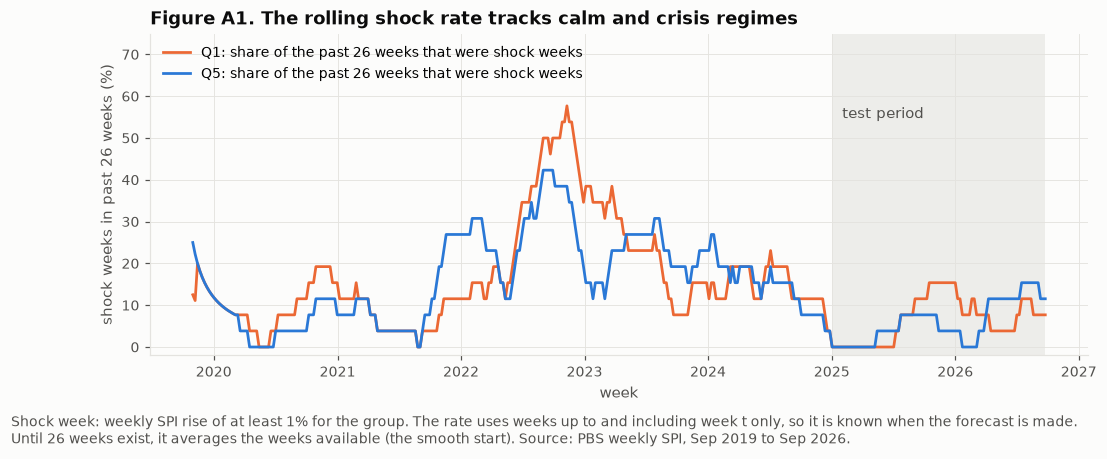

In [4]:
# Figure A1: the 26-week shock rate follows the inflation regime
fig, ax = plt.subplots(figsize=(11, 3.8))
for g in ["Q1", "Q5"]:
    s = df[df["group"] == g]
    ax.plot(s["week_end"], 100 * s["shock_rate_26w"], color=GROUP_COLORS[g], lw=1.8,
            label=f"{g}: share of the past 26 weeks that were shock weeks")
ax.axvspan(test["week_end"].min(), test["week_end"].max(), color=GRID, alpha=0.6, lw=0)
ax.text(test["week_end"].min(), ax.get_ylim()[1] * 0.95, "  test period", color=INK_SECONDARY, va="top")
ax.set(ylabel="shock weeks in past 26 weeks (%)", xlabel="week", ylim=(-2, 75),
       title="Figure A1. The rolling shock rate tracks calm and crisis regimes")
ax.legend(loc="upper left")
caption(fig, "Shock week: weekly SPI rise of at least 1% for the group. The rate uses weeks up to and including week t only, "
             "so it is known when the forecast is made.\nUntil 26 weeks exist, it averages "
             "the weeks available (the smooth start). Source: PBS weekly SPI, Sep 2019 to Sep 2026.", y=-0.03)
fig.savefig(FIG_DIR / "figA1_rolling_shock_rate.png")
plt.show()

**Reading the evidence (training years only)**
* Rows followed by a July week had a shock rate of **25.5%**, against 16.5% for all other rows, so the July effect is not
  only a test-period pattern. The one-week fiscal-year flag stays in the model too, because the week that contains
  1 July is still the riskiest single week (14 of its 25 training rows were followed by a shock).
* The 26-week shock rate separates calm and turbulent periods. Rows with a rate below 10% were followed by a shock
  **11.2%** of the time, rows between 10% and 20% **15.7%** of the time, and rows above 20% **23.5%** of the time.
* Figure A1 shows the regimes. The rate climbed above 40% in the 2022–23 crisis and fell to zero in early 2025. It
  overlaps with the shocks of the past four weeks (correlation 0.47) but looks much further back.

## 2. Validation design: time-ordered folds instead of shuffled stratified K-fold

The brief asks for hyperparameter tuning with stratified K-fold cross-validation and no data leakage. Stratification
keeps the share of shock rows about the same in every fold, so that no fold is left without the rare class. In our
data a stratified K-fold would draw rows at random, which leaks in two ways. It would train on later years to predict
earlier ones, and it would put the five quintile rows of one week, which share every week-level signal, on both sides
of the split. In Milestone 3 this inflated the AUC by 0.05 to 0.14.

We therefore keep the Milestone 3 folds and check that they give what stratification is meant to give.

* **K = 4 expanding-window folds.** Fold *k* validates on calendar year 2020 + *k* and trains on every week before it,
  so a model never sees a week later than the ones it predicts.
* **Whole weeks** stay together, so sister quintile rows never sit on both sides.
* **Both classes in every fold.** The table below shows that every validation year contains shock rows and calm rows
  for every quintile, which also makes a fairness comparison by quintile possible in every fold.
* The folds are identical to Milestone 3, so the scores of the old and new models are directly comparable.

In [5]:
folds = B.time_series_folds(train)
ft = B.fold_table(train, folds)
# Shock rows of each quintile in each validation year: every fold has both classes for every group
per_group = pd.DataFrame({f"shock rows {g}": [int(y.iloc[va][g_tr[va] == g].sum()) for _, va in folds] for g in A.GROUPS})
ft = pd.concat([ft, per_group], axis=1)
display(ft.round(1))
ft.to_csv(TABLE_DIR / "m4_cv_folds.csv", index=False)
for tr, va in folds:
    assert train["week_end"].iloc[tr].max() < train["week_end"].iloc[va].min()
val = np.concatenate([va for _, va in folds])      # rows of the four validation years
print("Every validation year contains shock and calm rows for every quintile:",
      bool((per_group > 0).all().all()))

,fold,train weeks,n train weeks,validation weeks,n validation weeks,train shock rate %,validation shock rate %,validation shocks (rows),shock rows Q1,shock rows Q2,shock rows Q3,shock rows Q4,shock rows Q5
0,1,31 Oct 2019 – 31 Dec 2020,62,07 Jan 2021 – 30 Dec 2021,52,9.4,13.1,34,4,7,7,8,8
1,2,31 Oct 2019 – 30 Dec 2021,114,06 Jan 2022 – 29 Dec 2022,52,11.1,33.1,86,19,19,18,18,12
2,3,31 Oct 2019 – 29 Dec 2022,166,05 Jan 2023 – 28 Dec 2023,52,18.0,20.0,52,9,11,8,11,13
3,4,31 Oct 2019 – 28 Dec 2023,218,04 Jan 2024 – 26 Dec 2024,52,18.4,11.9,31,6,6,7,7,5


Every validation year contains shock and calm rows for every quintile: True


**Leakage checklist for Milestone 4**

| Possible leak | How it is closed |
|---|---|
| Training on weeks later than the ones predicted | expanding window, asserted above |
| Sister quintile rows of the same week on both sides | folds are built from whole weeks |
| Scaling with validation or test statistics | scalers sit inside each pipeline and are re-fitted on each fold's training rows (the ensembles need no scaling) |
| New features that peek at week *t+1* | the 26-week shock rate uses weeks up to *t*; July is a calendar fact known in advance |
| Fairness weights computed on validation rows | reweighing and group weights (notebook 06) are computed on each fold's training rows only |
| Thresholds, fairness constraints or hyperparameters chosen on the test period | all are chosen on the 2021–24 out-of-fold predictions |

Two exceptions are disclosed. The seven "momentum" items behind `momentum_spikes_4w` were chosen in Milestone 2 on all
training weeks, so inside cross-validation that choice has seen later folds (never the test period). And, as noted in
§1, the two new features were motivated by the Milestone 3 test-period errors.

## 3. Models and search spaces

|  | Random forest | Gradient boosting |
|---|---|---|
| **How it works** | grows many decision trees, each on a bootstrap sample of the training rows and choosing every split from a random subset of the features, then averages their votes | adds small trees one at a time, each fitted to the errors that the trees before it still make, and adds a shrunken copy of it to the model (the learning rate sets how much) |
| **Why it suits this problem** | it keeps what a tree does well (thresholds such as "the rupee fell by more than 8%" and interactions such as a falling rupee before the budget) while averaging away the variance that made the single Milestone 3 tree unstable | it builds the interactions gradually and can be held back in several ways (learning rate, tree depth, leaf size, an L2 penalty), which matters with only 1,350 training rows |
| **Main weakness** | less transparent than one tree, and its probabilities are averages of leaf shares, so they need a calibration check | many settings to tune, and it overfits quickly if the learning rate is high and the trees are deep |
| **Search space** | depth 3, 5, 8 or unlimited; minimum leaf 5, 20, 50 or 100 rows; features per split √20 or half; Gini or entropy; class weights none or balanced (128 settings, 300 trees each) | learning rate 0.01, 0.03 or 0.1; 100 or 300 trees; depth 2 or 3; minimum leaf 20, 50 or 100; L2 penalty 0 or 1; class weights none or balanced (144 settings) |

The implementation is scikit-learn's `RandomForestClassifier` and `HistGradientBoostingClassifier`. The second is the
usual gradient boosting algorithm with one speed-up: each feature is first sorted into at most 255 bins, so split
points are searched among bins instead of among every distinct value. With 1,350 rows this changes little.

**The Milestone 3 learners are re-tuned under the same protocol** with their Milestone 3 grids plus the two options our
after-submission check found missing: the split criterion of the tree (Gini or entropy) and the distance of KNN
(Euclidean or Manhattan). The three of them also get the two new features. Comparing them with the ensembles separates
the gain from the new features and the new selection rule from the gain from ensembling.

**Selection rule: within-year AUC.** Each setting is ranked by the mean of its four per-year validation AUCs. Milestone 3
ranked by the AUC of the pooled out-of-fold predictions. We found afterwards that the pooled AUC partly rewards telling
crisis years from calm years (the tree's pooled AUC was higher than three of its four yearly AUCs), while the
within-year order of the learners was the order the test period reproduced. The level of the probabilities, which the
pooled AUC was meant to protect, is handled by the new 26-week shock rate and checked directly through calibration
(§9) and the cost of one shared threshold (§8). Pooled AUC, PR-AUC and the Brier score are reported next to it. The
rule was fixed before any Milestone 4 model was fitted. **The final model is the learner with the highest within-year
AUC.**

In [6]:
models, grids = A.make_models()
for name in MODELS:
    n = int(np.prod([len(v) for v in grids[name].values()]))
    print(f"{name}: {n} settings x {len(folds)} folds = {n * len(folds)} fits")
    for k, v in grids[name].items():
        print(f"    {k.split('__')[-1]:18s} {[type(x).__name__ if hasattr(x, 'fit') else x for x in v]}")

Logistic regression: 48 settings x 4 folds = 192 fits
    C                  [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
    l1_ratio           [0.0, 1.0]
    class_weight       [None, 'balanced']
KNN: 88 settings x 4 folds = 352 fits
    n_neighbors        [5, 10, 15, 25, 35, 50, 75, 100, 150, 200, 250]
    weights            ['uniform', 'distance']
    metric             ['euclidean', 'manhattan']
    cont               ['StandardScaler', 'MinMaxScaler']
Decision tree: 196 settings x 4 folds = 784 fits
    max_depth          [1, 2, 3, 4, 5, 6, 8]
    min_samples_leaf   [5, 10, 20, 40, 80, 120, 160]
    criterion          ['gini', 'entropy']
    class_weight       [None, 'balanced']
Random forest: 128 settings x 4 folds = 512 fits
    max_depth          [3, 5, 8, None]
    min_samples_leaf   [5, 20, 50, 100]
    max_features       ['sqrt', 0.5]
    criterion          ['gini', 'entropy']
    class_weight       [None, 'balanced_subsample']
Gradient boosting: 144 

## 4. Tuning results

Every setting is trained on each fold's training weeks and predicts that fold's validation year. The tables show the
three best settings of each learner. "train AUC" is the AUC on each fold's own training weeks, kept to see over- and
underfitting.

In [7]:
# Grid search for all five learners (takes a few minutes; the random forest is the slowest)
grid_res, fitted, oof = {}, {}, {}
for name in MODELS:
    res, best, oof[name] = A.tune(models[name], grids[name], X, y, folds)
    fitted[name], grid_res[name] = best, res
    res.drop(columns="_params").to_csv(TABLE_DIR / f"m4_cv_grid_{name.lower().replace(' ', '_')}.csv", index=False)
    print(f"\n{name}: top 3 of {len(res)} settings (sorted by within-year AUC)")
    show = [c for c in res.columns if c not in ("_params", "selected", "AUC 1", "AUC 2", "AUC 3", "AUC 4")]
    display(res[show].head(3).round(3))


Logistic regression: top 3 of 48 settings (sorted by within-year AUC)


,C,class_weight,l1_ratio,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
0,0.0,balanced,0.0,0.640,0.035,0.635,0.320,0.247,0.791
1,0.0,NaN,0.0,0.640,0.033,0.533,0.237,0.163,0.790
2,0.0,NaN,0.0,0.639,0.035,0.530,0.234,0.162,0.792



KNN: top 3 of 88 settings (sorted by within-year AUC)


,metric,n_neighbors,weights,cont,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
0,manhattan,250,distance,StandardScaler,0.683,0.099,0.649,0.302,0.155,1.000
1,manhattan,250,uniform,StandardScaler,0.679,0.094,0.644,0.292,0.155,0.746
2,manhattan,200,distance,StandardScaler,0.668,0.092,0.648,0.305,0.155,1.000



Decision tree: top 3 of 196 settings (sorted by within-year AUC)


,class_weight,criterion,max_depth,min_samples_leaf,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
0,NaN,entropy,4,80,0.657,0.070,0.601,0.280,0.161,0.802
1,NaN,entropy,5,80,0.657,0.071,0.608,0.282,0.161,0.812
2,NaN,entropy,6,80,0.653,0.073,0.607,0.281,0.161,0.814



Random forest: top 3 of 128 settings (sorted by within-year AUC)


,class_weight,criterion,max_depth,max_features,min_samples_leaf,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
0,NaN,gini,5.0,sqrt,20,0.678,0.060,0.651,0.305,0.152,0.932
1,balanced_subsample,gini,NaN,sqrt,5,0.676,0.031,0.626,0.305,0.164,0.997
2,NaN,gini,3.0,sqrt,20,0.675,0.066,0.649,0.308,0.152,0.896



Gradient boosting: top 3 of 144 settings (sorted by within-year AUC)


,class_weight,l2_regularization,learning_rate,max_depth,max_iter,min_samples_leaf,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
0,NaN,0.0,0.01,2,300,50,0.635,0.030,0.639,0.310,0.155,0.924
1,NaN,1.0,0.03,2,100,50,0.634,0.043,0.642,0.308,0.154,0.920
2,NaN,1.0,0.01,2,300,50,0.633,0.037,0.640,0.303,0.155,0.920


In [8]:
# Selected setting of each learner
rows = []
for name in MODELS:
    top = grid_res[name].iloc[0]
    rows.append({"model": name, "selected setting": ", ".join(f"{k}={v}" for k, v in B._short(top["_params"]).items()),
                 **A.cv_scores(y, oof[name], folds), "train AUC": top["train AUC"]})
cv_m4 = pd.DataFrame(rows).set_index("model")
display(cv_m4.drop(columns="selected setting").round(3))
cv_m4.to_csv(TABLE_DIR / "m4_cv_summary.csv")
# Final model: the highest within-year AUC among the learners that accept training weights, because the
# pre- and in-processing mitigations of notebook 06 retrain the final model with row weights
cv_m4["accepts row weights"] = [has_fit_parameter(fitted[n].named_steps["model"], "sample_weight") for n in MODELS]
FINAL = cv_m4[cv_m4["accepts row weights"]]["within-year AUC"].idxmax()
print("Selected settings:")
for n in MODELS:
    print(f"  {n}: {cv_m4.loc[n, 'selected setting']}")
best_any = cv_m4["within-year AUC"].idxmax()
print(f"\nHighest within-year AUC overall: {best_any} ({cv_m4.loc[best_any, 'within-year AUC']:.3f})")
print(f"Final model (highest within-year AUC among learners that accept row weights): {FINAL} "
      f"({cv_m4.loc[FINAL, 'within-year AUC']:.3f})")

,within-year AUC,within-year SD,AUC 1,AUC 2,AUC 3,AUC 4,pooled AUC,pooled PR-AUC,pooled Brier,train AUC
model,,,,,,,,,,
Logistic regression,0.640,0.035,0.684,0.641,0.650,0.586,0.635,0.320,0.247,0.791
KNN,0.683,0.099,0.843,0.616,0.684,0.587,0.649,0.302,0.155,1.000
Decision tree,0.657,0.070,0.739,0.554,0.700,0.636,0.601,0.280,0.161,0.802
Random forest,0.678,0.060,0.774,0.625,0.684,0.629,0.651,0.305,0.152,0.932
Gradient boosting,0.635,0.030,0.662,0.637,0.654,0.585,0.639,0.310,0.155,0.924


Selected settings:
  Logistic regression: C=0.0001, class_weight=balanced, l1_ratio=0.0
  KNN: metric=manhattan, n_neighbors=250, weights=distance, cont=StandardScaler
  Decision tree: class_weight=None, criterion=entropy, max_depth=4, min_samples_leaf=80
  Random forest: class_weight=None, criterion=gini, max_depth=5, max_features=sqrt, min_samples_leaf=20
  Gradient boosting: class_weight=None, l2_regularization=0.0, learning_rate=0.01, max_depth=2, max_iter=300, min_samples_leaf=50

Highest within-year AUC overall: KNN (0.683)
Final model (highest within-year AUC among learners that accept row weights): Random forest (0.678)


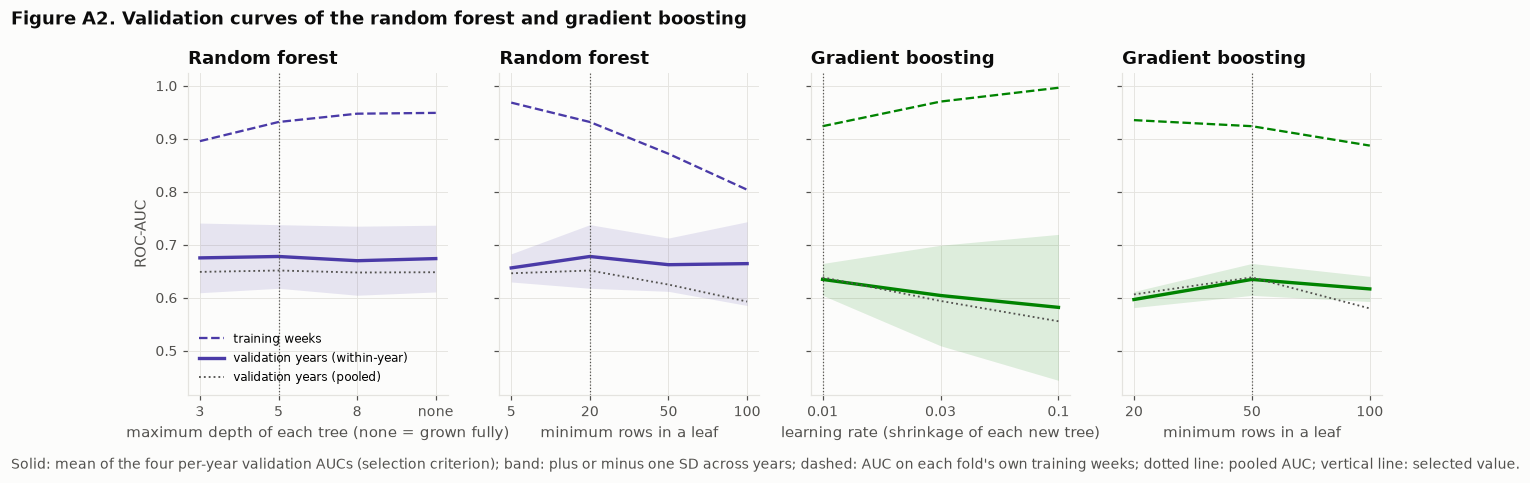

In [9]:
# Figure A2: validation curves of the two ensembles
def same(col, v):
    # numbers are compared as numbers (5 and 5.0 are equal), None as missing, text as text
    if v is None:
        return col.isna()
    if isinstance(v, (int, float)) and not isinstance(v, bool):
        return (pd.to_numeric(col, errors="coerce") - float(v)).abs() < 1e-9
    return col.astype(str) == str(v)

def curve(name, xparam, fixed):
    r = grid_res[name].copy()
    for k, v in fixed.items():
        r = r[same(r[k], v)]
    return r.sort_values(xparam, key=lambda s: pd.to_numeric(s, errors="coerce").fillna(99))

sel = {n: B._short(grid_res[n].iloc[0]["_params"]) for n in A.ENSEMBLES}
specs = [("Random forest", "max_depth", "maximum depth of each tree (none = grown fully)"),
         ("Random forest", "min_samples_leaf", "minimum rows in a leaf"),
         ("Gradient boosting", "learning_rate", "learning rate (shrinkage of each new tree)"),
         ("Gradient boosting", "min_samples_leaf", "minimum rows in a leaf")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, (name, xp, xlabel) in zip(axes, specs):
    c = curve(name, xp, {k: v for k, v in sel[name].items() if k != xp})
    xs = c[xp].fillna(-1).astype(float).to_numpy()
    lab = ["none" if v == -1 else (f"{v:g}") for v in xs]
    pos = np.arange(len(xs))
    ax.plot(pos, c["train AUC"], ls="--", color=COLORS[name], lw=1.5, label="training weeks")
    ax.plot(pos, c["within-year AUC"], color=COLORS[name], lw=2.2, label="validation years (within-year)")
    ax.fill_between(pos, c["within-year AUC"] - c["within-year SD"], c["within-year AUC"] + c["within-year SD"],
                    color=COLORS[name], alpha=0.12, lw=0)
    ax.plot(pos, c["pooled AUC"], color=INK_SECONDARY, lw=1.2, ls=":", label="validation years (pooled)")
    chosen = list(xs).index(-1 if sel[name][xp] is None else float(sel[name][xp]))
    ax.axvline(chosen, color=INK_SECONDARY, lw=0.8, ls=":")
    ax.set_xticks(pos, lab)
    ax.set(xlabel=xlabel, title=name)
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure A2. Validation curves of the random forest and gradient boosting", x=0.01, ha="left",
             fontweight="bold", color=INK, y=1.03)
caption(fig, "Solid: mean of the four per-year validation AUCs (selection criterion); band: plus or minus one SD across years; "
             "dashed: AUC on each fold's own training weeks; dotted line: pooled AUC; vertical line: selected value.", y=-0.04)
fig.savefig(FIG_DIR / "figA2_validation_curves_ensembles.png")
plt.show()

**Reading the tuning results**
* **Random forest.** The best setting grows trees of depth 5 with leaves of at least 20 rows, about four features per
  split (√20), the Gini criterion and no class weights. Its within-year AUC is **0.678** (SD 0.060 across the four
  years) and its pooled AUC 0.651. Figure A2 shows where overfitting starts. Leaves of 5 rows push the training AUC to
  0.97 but validate at 0.656, while leaves of 20 validate at 0.678 and larger leaves underfit (0.66). Depth hardly
  matters once leaves are 20 rows (0.670 to 0.678), and 9 of the 128 settings are within 0.01 of the best, so the forest
  is not sensitive to the exact choice. Gini beat entropy for the forest (0.678 against 0.663).
* **Gradient boosting** prefers the slowest learning: a learning rate of 0.01 with 300 trees of depth 2 and leaves of
  50 rows, within-year AUC **0.635**. Faster learning overfits clearly. At a learning rate of 0.1 with 300 trees the
  training AUC reaches 0.996 while the validation AUC falls to 0.582. With a weak signal, each tree that corrects the
  last one's errors soon starts to fit noise.
* **The re-tuned Milestone 3 learners.** KNN now uses the Manhattan distance with k = 250 neighbours weighted by
  distance (0.683; the best Euclidean setting reaches 0.661). The tree now splits by entropy, but most of its rise from
  0.578 to 0.657 comes from the new selection rule, because the best Gini tree under the within-year rule already
  reaches 0.653. Logistic regression keeps its Milestone 3 setting and scores 0.640. KNN's training AUC of 1.0 is not
  overfitting in itself. With distance weights, every training row is its own nearest neighbour.
* **The five learners are statistically tied.** Their within-year AUCs span 0.635 to 0.683, while the year-to-year SDs
  are 0.03 to 0.10. Every learner finds 2021 the easiest validation year, and 2022 or 2024 the hardest.
* **Final model: the random forest.** KNN has the highest within-year AUC (0.683), but it cannot be retrained with row
  weights, which the pre- and in-processing bias mitigations of notebook 06 need. Among the learners that can, the
  forest is best (0.678). The gap to KNN (0.005) is about one twelfth of KNN's year-to-year SD. The forest is also
  steadier across years and has the best pooled AUC, the best Brier score and the lowest validation cost at its
  threshold.

## 5. Comparison with the Milestone 3 baselines

The Milestone 3 models are loaded exactly as submitted (18 features, their settings and their thresholds) and checked
against their submitted cross-validated AUCs. Their out-of-fold predictions are rebuilt on the same folds. They are
compared with the five learners under the Milestone 4 protocol on every metric of the brief.

* **Cross-validated (2021–24):** within-year AUC (the new selection rule), pooled AUC, PR-AUC and Brier score.
* **Test period (2025–26):** accuracy, precision, recall, F1, ROC-AUC, PR-AUC, Brier score and the expected cost of errors
  relative to never raising an alarm, at each model's threshold. The threshold minimises the cost of errors on the
  2021–24 out-of-fold predictions, with a missed shock costing five false alarms, as in Milestone 3.

Accuracy is reported because the brief asks for it, but it cannot be used to choose an alarm model. Never raising an
alarm scores 92.3% on the test period while catching no shock.

In [10]:
card3 = json.loads((ROOT / "models" / "m3_baselines" / "model_card.json").read_text(encoding="utf-8"))
M3 = ["Logistic regression", "KNN", "Decision tree"]
m3_fit = {n: joblib.load(ROOT / "models" / "m3_baselines" / (n.lower().replace(" ", "_") + ".joblib")) for n in M3}
m3_thr = {n: card3["models"][n]["threshold"] for n in M3}
X3, Xt3 = train[B.FEATURES], test[B.FEATURES]
m3_oof = {n: B.oof_predict(m3_fit[n], X3, y, folds) for n in M3}
m3_test = {n: m3_fit[n].predict_proba(Xt3)[:, 1] for n in M3}
pers = B.Persistence().fit(X3, y)
m3_oof["Persistence"], m3_test["Persistence"] = B.oof_predict(pers, X3, y, folds), pers.predict_proba(Xt3)[:, 1]
m3_thr["Persistence"] = 0.5
for n in M3:
    assert abs(roc_auc_score(y[val], m3_oof[n][val]) - card3["models"][n]["pooled_cv_auc"]) < 1e-9

In [11]:
# One table: M3 baselines against the five learners under the M4 protocol
thr = {n: B.best_threshold(y, oof[n]) for n in MODELS}            # cost 5:1 on 2021-24 out-of-fold predictions
p_test = {n: fitted[n].predict_proba(Xt)[:, 1] for n in MODELS}
entries = [(f"M3 {n}", m3_oof[n], m3_test[n], m3_thr[n]) for n in M3 + ["Persistence"]] + \
          [(f"M4 {n}", oof[n], p_test[n], thr[n]) for n in MODELS]
never_val, never_test = B.COST_FN * y[val].sum(), B.COST_FN * yt.sum()
rows = []
for lab, po, pt, t in entries:
    cv = A.cv_scores(y, po, folds)
    m = B.classification_metrics(yt, pt, t)
    rows.append({"model": lab, "CV within-year AUC": cv["within-year AUC"], "CV pooled AUC": cv["pooled AUC"],
                 "CV PR-AUC": cv["pooled PR-AUC"], "CV Brier": cv["pooled Brier"], "threshold": t,
                 "test accuracy": m["accuracy"], "test precision": m["precision"], "test recall": m["recall"],
                 "test F1": m["F1"], "test ROC-AUC": m["ROC-AUC"], "test PR-AUC": m["PR-AUC"], "test Brier": m["Brier"],
                 "CV cost / never": B.expected_cost(y[val], po[val], t) / never_val,
                 "test cost / never": m["cost"] / never_test})
comp = pd.DataFrame(rows).set_index("model")
display(comp.round(3))
comp.to_csv(TABLE_DIR / "m4_model_comparison.csv")

,CV within-year AUC,CV pooled AUC,CV PR-AUC,CV Brier,threshold,test accuracy,test precision,test recall,test F1,test ROC-AUC,test PR-AUC,test Brier,CV cost / never,test cost / never
model,,,,,,,,,,,,,,
M3 Logistic regression,0.651,0.643,0.328,0.247,0.50,0.855,0.140,0.171,0.154,0.567,0.114,0.238,0.674,1.040
M3 KNN,0.672,0.643,0.288,0.154,0.12,0.675,0.131,0.571,0.213,0.679,0.141,0.070,0.651,1.189
M3 Decision tree,0.578,0.652,0.293,0.160,0.16,0.745,0.099,0.286,0.147,0.541,0.087,0.078,0.612,1.234
M3 Persistence,0.569,0.584,0.240,0.262,0.50,0.851,0.029,0.029,0.029,0.474,0.076,0.149,0.804,1.166
M4 Logistic regression,0.640,0.635,0.320,0.247,0.50,0.862,0.182,0.229,0.203,0.601,0.119,0.236,0.706,0.977
M4 KNN,0.683,0.649,0.302,0.155,0.11,0.697,0.135,0.543,0.216,0.643,0.152,0.069,0.665,1.154
M4 Decision tree,0.657,0.601,0.280,0.161,0.02,0.275,0.096,1.000,0.175,0.687,0.117,0.072,0.740,1.886
M4 Random forest,0.678,0.651,0.305,0.152,0.14,0.719,0.140,0.514,0.220,0.674,0.126,0.072,0.651,1.120
M4 Gradient boosting,0.635,0.639,0.310,0.155,0.14,0.745,0.142,0.457,0.216,0.650,0.120,0.072,0.677,1.097


In [12]:
# Uncertainty on the test period: 2,000 bootstrap resamples of whole test weeks
scores = {f"M4 {n}": p_test[n] for n in MODELS}
scores.update({f"M3 {n}": m3_test[n] for n in M3})
boot = B.week_block_bootstrap(yt, scores, test["week_end"])
ci = pd.DataFrame({"test AUC": [comp.loc[k, "test ROC-AUC"] for k in boot.columns],
                   "95% CI low": boot.quantile(0.025).values, "95% CI high": boot.quantile(0.975).values},
                  index=boot.columns)
display(ci.round(3))
ref = "M3 KNN" # the best M3 baseline on the test period
gain = []
for n in MODELS:
    d = boot[f"M4 {n}"] - boot[ref]
    gain.append({"comparison": f"M4 {n} minus {ref}", "AUC difference": comp.loc[f"M4 {n}", "test ROC-AUC"] - comp.loc[ref, "test ROC-AUC"],
                 "95% CI low": d.quantile(0.025), "95% CI high": d.quantile(0.975), "share of resamples <= 0": (d <= 0).mean()})
gain = pd.DataFrame(gain).set_index("comparison")
display(gain.round(3))
ci.to_csv(TABLE_DIR / "m4_test_auc_ci.csv")
gain.to_csv(TABLE_DIR / "m4_test_auc_gain_vs_m3.csv")

,test AUC,95% CI low,95% CI high
M4 Logistic regression,0.601,0.372,0.783
M4 KNN,0.643,0.407,0.812
M4 Decision tree,0.687,0.546,0.812
M4 Random forest,0.674,0.491,0.814
M4 Gradient boosting,0.650,0.487,0.791
M3 Logistic regression,0.567,0.354,0.757
M3 KNN,0.679,0.469,0.833
M3 Decision tree,0.541,0.427,0.668


,AUC difference,95% CI low,95% CI high,share of resamples <= 0
comparison,,,,
M4 Logistic regression minus M3 KNN,-0.078,-0.156,0.001,0.973
M4 KNN minus M3 KNN,-0.036,-0.118,0.030,0.835
M4 Decision tree minus M3 KNN,0.008,-0.150,0.168,0.429
M4 Random forest minus M3 KNN,-0.005,-0.104,0.106,0.530
M4 Gradient boosting minus M3 KNN,-0.029,-0.196,0.148,0.608


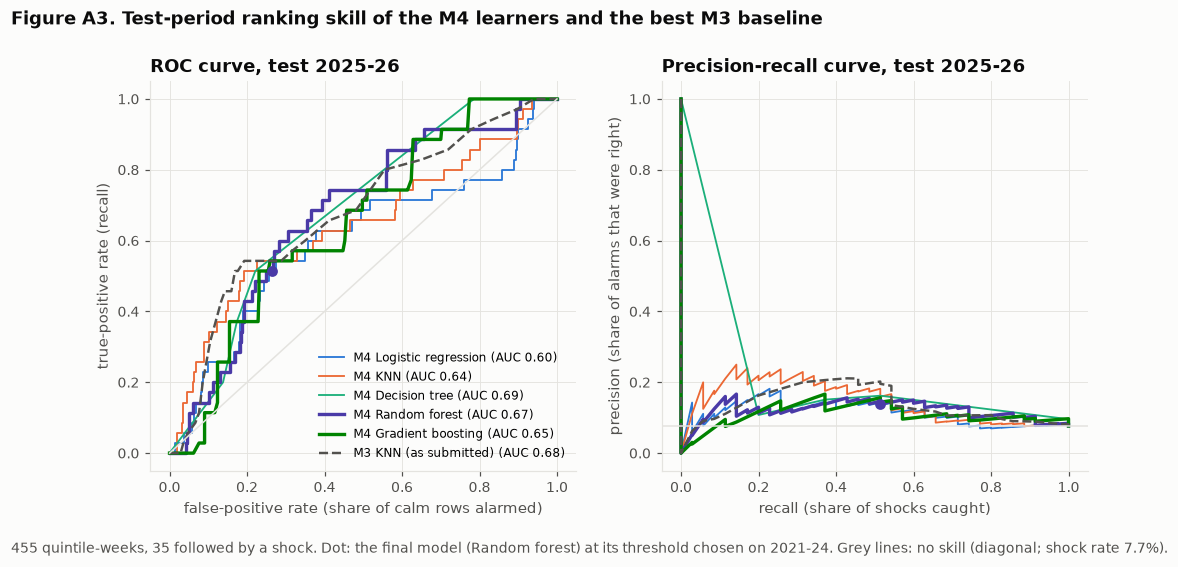

In [13]:
# Figure A3: ROC and precision-recall curves on the test period, M4 learners against the best M3 baseline
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
curves = [(f"M4 {n}", p_test[n], COLORS[n], "-", 2.2 if n in A.ENSEMBLES else 1.2) for n in MODELS] + \
         [("M3 KNN (as submitted)", m3_test["KNN"], INK_SECONDARY, "--", 1.6)]
for lab, pt, col, ls, lw in curves:
    fpr, tpr, _ = roc_curve(yt, pt)
    a1.plot(fpr, tpr, color=col, ls=ls, lw=lw, label=f"{lab} (AUC {roc_auc_score(yt, pt):.2f})")
    pr, rc, _ = precision_recall_curve(yt, pt)
    a2.plot(rc, pr, color=col, ls=ls, lw=lw, label=lab)
for n in [FINAL]:
    mm = B.classification_metrics(yt, p_test[n], thr[n])
    fpr_pt = mm["FP"] / (mm["FP"] + mm["TN"])
    a1.scatter(fpr_pt, mm["recall"], color=COLORS[n], s=50, zorder=5, edgecolor=INK)
    a2.scatter(mm["recall"], mm["precision"], color=COLORS[n], s=50, zorder=5, edgecolor=INK)
a1.plot([0, 1], [0, 1], color=GRID, lw=1)
a2.axhline(yt.mean(), color=GRID, lw=1)
a1.set(xlabel="false-positive rate (share of calm rows alarmed)", ylabel="true-positive rate (recall)",
       title="ROC curve, test 2025-26")
a2.set(xlabel="recall (share of shocks caught)", ylabel="precision (share of alarms that were right)",
       title="Precision-recall curve, test 2025-26")
a1.legend(loc="lower right", fontsize=8)
fig.suptitle("Figure A3. Test-period ranking skill of the M4 learners and the best M3 baseline", x=0.01, ha="left",
             fontweight="bold", color=INK, y=1.02)
caption(fig, f"455 quintile-weeks, 35 followed by a shock. Dot: the final model ({FINAL}) at its threshold chosen on 2021-24. "
             "Grey lines: no skill (diagonal; shock rate 7.7%).", y=-0.03)
fig.savefig(FIG_DIR / "figA3_roc_pr_test.png")
plt.show()

**Reading the comparison**
* **In cross-validation the gains come from re-tuning, not from ensembling.** The best Milestone 3 baseline (KNN) had a
  within-year AUC of 0.672. The random forest reaches 0.678 and the re-tuned KNN 0.683, differences far smaller than the
  year-to-year SD. The forest, KNN and gradient boosting have Brier scores of 0.152 to 0.155, slightly better than
  predicting the average shock rate (0.158).
* **On the test period the forest matches, but does not beat, the best baseline.** Its ROC-AUC is 0.674 against 0.679
  for the Milestone 3 KNN. The bootstrap interval of the difference runs from −0.10 to +0.11 and is centred on zero. With
  13 shock weeks, no learner is clearly better than another. The decision tree has the highest test AUC (0.687), but it
  was among the weaker learners in the validation years, and choosing it now would mean choosing on the test period.
* **At its threshold of 0.14 the forest caught 18 of the 35 shock rows** (recall 0.51) with 111 false alarms (precision
  0.14, F1 0.22). The Milestone 3 KNN caught 20 with 133 false alarms (F1 0.21).
* **The cost of errors is still above "never alert" in the test period** (1.12 for the forest, 1.19 for the Milestone 3
  KNN). Only logistic regression stays just below (0.98), because its probabilities sit near 0.5 and it rarely alerts.
  §8 explains why no threshold could have done better in 2025–26.
* **Accuracy misleads again.** Logistic regression has the highest accuracy of the five (0.86) because it alerts least,
  and the tree the lowest (0.28) because its threshold of 0.02 alerts in four test weeks out of five.

## 6. Where does the change come from?

The final model's selected setting is retrained four times on the same folds, with the 18 Milestone 3 features, with
each new feature added on its own, and with both. Cross-validated scores never use the test period, so this is the
cleanest evidence on the two new features.

In [14]:
# the change comes from the final model's setting, retrained with and without the new features
final_params = grid_res[FINAL].iloc[0]["_params"]
variants = {"18 features of M3": B.FEATURES,
            "+ shock rate, past 26 weeks": B.FEATURES + ["shock_rate_26w"],
            "+ next week in July": B.FEATURES + ["july_next_week"],
            "+ both (M4 features)": A.FEATURES}
rows = []
for lab, cols in variants.items():
    est = clone(models[FINAL]).set_params(**final_params)
    po = A.oof_predict(est, train[cols], y, folds)
    m = clone(est).fit(train[cols], y)
    pt = m.predict_proba(test[cols])[:, 1]
    t = B.best_threshold(y, po)
    rows.append({"features": lab, **{k: v for k, v in A.cv_scores(y, po, folds).items() if not k.startswith("AUC ")},
                 "test ROC-AUC": roc_auc_score(yt, pt), "test Brier": B.classification_metrics(yt, pt, t)["Brier"],
                 "test cost / never": B.expected_cost(yt, pt, t) / never_test})
ablation = pd.DataFrame(rows).set_index("features")
display(ablation.round(3))
ablation.to_csv(TABLE_DIR / "m4_feature_ablation.csv")

,within-year AUC,within-year SD,pooled AUC,pooled PR-AUC,pooled Brier,test ROC-AUC,test Brier,test cost / never
features,,,,,,,,
18 features of M3,0.684,0.073,0.657,0.307,0.152,0.669,0.073,1.120
"+ shock rate, past 26 weeks",0.676,0.072,0.651,0.303,0.153,0.684,0.072,1.109
+ next week in July,0.684,0.081,0.658,0.306,0.152,0.678,0.072,1.040
+ both (M4 features),0.678,0.060,0.651,0.305,0.152,0.674,0.072,1.120


**Reading the ablation**
* **The new features did not improve the ranking.** With the 18 Milestone 3 features the forest's within-year AUC is
  0.684. Adding the 26-week shock rate lowers it to 0.676, the July window leaves it at 0.684, and both give 0.678.
  These differences are about a tenth of the year-to-year SD, so the new features have no clear effect on ranking.
* With both features the forest is steadier across years (SD 0.060 against 0.073), and its pooled Brier score is
  unchanged (0.152).
* In the test period the July window alone lowered the cost of errors (1.04 against 1.12), but this is the period that
  suggested the feature, so we do not count it as evidence.
* The 26-week rate was meant to fix the threshold problem. §8 and §9 show that it did not. The features stay in the
  model as designed, because dropping them now would be a choice made after seeing the test period. Milestone 5, with
  new weeks, will decide whether to keep them.

## 7. Leakage check: what would shuffled stratified K-fold have reported?

As in Milestone 3, the tuned ensembles are re-scored with two designs that ignore time. Shuffled stratified K-fold over
rows is the textbook default. The whole-weeks version keeps a week's five rows together but still lets later years
predict earlier ones.

In [15]:
# Leakage check: what the shuffled stratified K-fold would have reported for the two ensembles?
designs = {"Shuffled stratified K-fold (rows)": B.random_folds(train),
           "Shuffled stratified K-fold (whole weeks)": B.random_folds(train, by_week=True),
           "Expanding window by year (ours)": folds}
rows = []
for name in A.ENSEMBLES:
    for d, f in designs.items():
        s = cross_val_score(fitted[name], X, y, cv=f, scoring="roc_auc")
        rows.append({"model": name, "CV design": d, "mean fold AUC": s.mean(), "fold AUC SD": s.std()})
leak = pd.DataFrame(rows).pivot(index="model", columns="CV design", values="mean fold AUC")[list(designs)]
display(leak.round(3))
leak.to_csv(TABLE_DIR / "m4_cv_design_comparison.csv")

CV design,Shuffled stratified K-fold (rows),Shuffled stratified K-fold (whole weeks),Expanding window by year (ours)
model,,,
Gradient boosting,0.799,0.651,0.635
Random forest,0.830,0.693,0.678


**Reading the leakage check.** Shuffled stratified K-fold over rows reports within-fold AUCs of **0.830** for the
forest and **0.799** for gradient boosting, against 0.678 and 0.635 with our design. That is 0.15 to 0.16 too
optimistic, a larger inflation than for the Milestone 3 baselines (0.05 to 0.14), because flexible ensembles find the
sister quintile rows of the same week and copy their outcome. Keeping a week's rows together removes most of the gap
(0.693 and 0.651), and the rest comes from training on later years. The time-ordered folds are the only design here
without leakage.

## 8. Threshold curves and asymmetric error costs

An alarm needs a cut-off on the predicted probability. As in Milestone 3, a missed shock is counted as five false
alarms (the ratio was justified in the Milestone 3 report, and ratios from 1 to 20 are shown below), and the threshold
is the value with the lowest cost of errors on the 2021–24 out-of-fold predictions. The curves show how precision,
recall, F1 and the cost change with the threshold, in the validation years and in the test period. Notebook 06 sets
a separate threshold for each quintile.

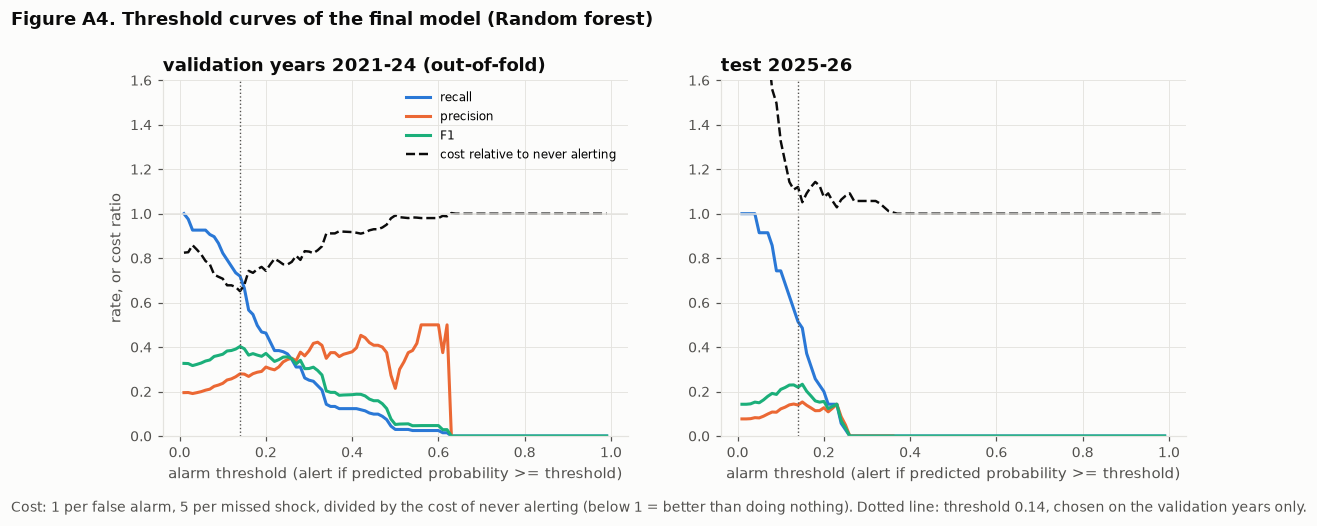

In [16]:
# Threshold curves of the final model: precision, recall, F1 and expected cost at every cut-off
grid_t = np.round(np.arange(0.01, 1.0, 0.01), 2)
def sweep(yy, pp):
    out = []
    for t in grid_t:
        m = B.classification_metrics(yy, pp, t)
        out.append({"threshold": t, "precision": m["precision"], "recall": m["recall"], "F1": m["F1"],
                    "alert rate": m["alerts"] / len(yy), "cost / never": m["cost"] / (B.COST_FN * np.sum(yy))})
    return pd.DataFrame(out)
sw_val, sw_test = sweep(y[val].to_numpy(), oof[FINAL][val]), sweep(yt.to_numpy(), p_test[FINAL])
sw_val.to_csv(TABLE_DIR / "m4_threshold_curve_oof.csv", index=False)
sw_test.to_csv(TABLE_DIR / "m4_threshold_curve_test.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, sw, lab in [(axes[0], sw_val, "validation years 2021-24 (out-of-fold)"), (axes[1], sw_test, "test 2025-26")]:
    ax.plot(sw["threshold"], sw["recall"], color=SERIES[0], label="recall")
    ax.plot(sw["threshold"], sw["precision"], color=SERIES[1], label="precision")
    ax.plot(sw["threshold"], sw["F1"], color=SERIES[2], label="F1")
    ax.plot(sw["threshold"], sw["cost / never"], color=INK, lw=1.6, ls="--", label="cost relative to never alerting")
    ax.axvline(thr[FINAL], color=INK_SECONDARY, lw=0.9, ls=":")
    ax.axhline(1, color=GRID, lw=1)
    ax.set(xlabel="alarm threshold (alert if predicted probability >= threshold)", title=lab, ylim=(0, 1.6))
axes[0].set_ylabel("rate, or cost ratio")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle(f"Figure A4. Threshold curves of the final model ({FINAL})", x=0.01, ha="left", fontweight="bold",
             color=INK, y=1.03)
caption(fig, f"Cost: 1 per false alarm, 5 per missed shock, divided by the cost of never alerting (below 1 = better than doing nothing). "
             f"Dotted line: threshold {thr[FINAL]:.2f}, chosen on the validation years only.", y=-0.03)
fig.savefig(FIG_DIR / "figA4_threshold_curves.png")
plt.show()

In [17]:
# Sensitivity to the cost ratio: threshold re-chosen on 2021-24 for each ratio, then scored on the test period
rows = []
for r in B.COST_RATIOS:
    triv_oof, triv_test = B.trivial_policy_costs(y[val], 1, r), B.trivial_policy_costs(yt, 1, r)
    for lab, po, pt in [(f"M4 {FINAL}", oof[FINAL], p_test[FINAL]), ("M3 KNN", m3_oof["KNN"], m3_test["KNN"])]:
        t = B.best_threshold(y, po, 1, r)
        rows.append({"FN : FP": f"{r} : 1", "model": lab, "threshold": t,
                     "2021-24 cost / cheaper trivial": B.expected_cost(y[val], po[val], t, 1, r) / min(triv_oof.values()),
                     "test cost / cheaper trivial": B.expected_cost(yt, pt, t, 1, r) / min(triv_test.values())})
ratios = pd.DataFrame(rows)
display(ratios.pivot(index="FN : FP", columns="model",
                     values=["threshold", "2021-24 cost / cheaper trivial", "test cost / cheaper trivial"])
        .reindex([f"{r} : 1" for r in B.COST_RATIOS]).round(2))
ratios.to_csv(TABLE_DIR / "m4_cost_ratio_sensitivity.csv", index=False)

threshold                  2021-24 cost / cheaper trivial                  test cost / cheaper trivial                 
model      M3 KNN M4 Random forest                         M3 KNN M4 Random forest                      M3 KNN M4 Random forest
FN : FP                                                                                                                        
1 : 1        0.76             0.79                           1.00             1.00                        1.00             1.00
2 : 1        0.33             0.31                           0.95             0.93                        1.03             1.14
3 : 1        0.17             0.28                           0.84             0.86                        1.19             1.10
5 : 1        0.12             0.14                           0.79             0.79                        1.19             1.12
10 : 1       0.01             0.01                           1.04             1.00                        1.18             1.20
20 : 1       0.01             0.01                           1.10             1.00                        0.99             1.00

**Reading the threshold curves and costs**
* **Validation years (2021–24).** At the threshold of 0.14 the forest catches 72% of shock rows with a precision of
  0.28, and the cost of its errors is 0.65 of the cost of never alerting.
* **Why no threshold works in the test period.** With a missed shock costing five false alarms, an alarm pays off only
  if more than one alarm in six is right (precision above 1/6 = 0.167). In 2021–24, when 19.5% of rows were followed by a
  shock, the forest's alarms cleared that bar easily. In 2025–26 only 7.7% were, and the forest's precision never rose
  above 0.153 at any threshold that raised at least ten alarms. The best policy in the test period was therefore never
  to alert. Its most confident alarms were also wrong, since every test row with a probability of 0.26 or more was a calm
  week.
* **Cost ratios.** At 2 : 1 to 5 : 1 the forest beats the cheaper trivial policy in 2021–24 (0.79 to 0.93 of its cost)
  but not in the test period at any ratio (1.00 to 1.20), much like the Milestone 3 KNN. A threshold learned in a
  crisis regime still does not transfer to a calm one. Milestone 5 will re-choose the threshold on recent weeks.

## 9. Calibration: do the probabilities mean what they say?

A probability of 0.2 should be followed by a shock about one time in five. We sort the predictions into eight groups
of equal size and compare the mean prediction with the observed shock rate in each group, and we report the Brier score
(the mean squared difference between the probability and the 0/1 outcome, lower is better). The Brier score of always
predicting the training shock rate is the reference. Calibration matters here for two reasons. A single threshold only
works across years if the probabilities keep their meaning, and hypothesis H5 (notebook 06) compares Q1 and Q5 on the
Brier score.

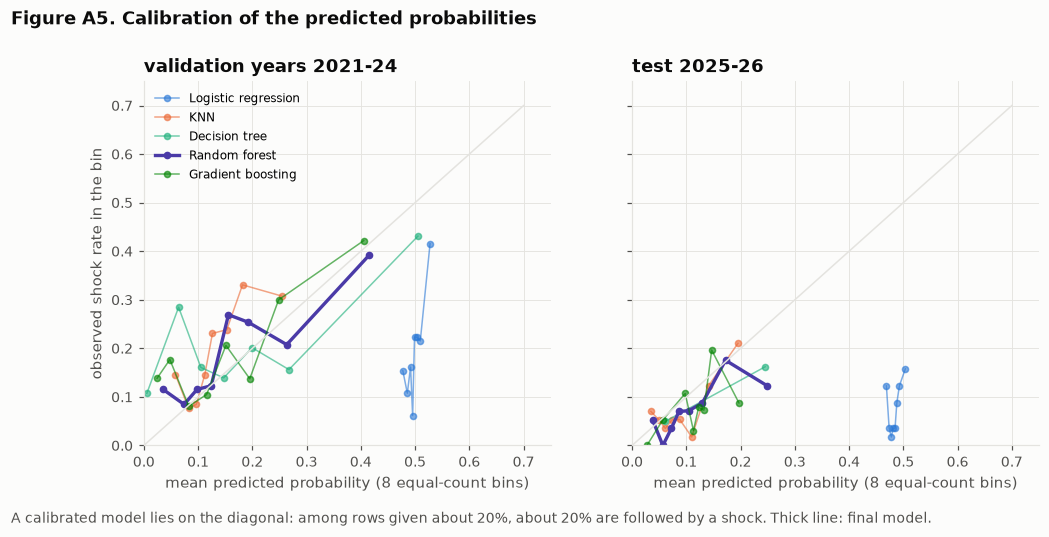

Brier                          mean predicted                         
period              test 2025-26 validation years 2021-24   test 2025-26 validation years 2021-24
model                                                                                            
Decision tree              0.072                    0.161          0.106                    0.153
Gradient boosting          0.072                    0.155          0.111                    0.158
KNN                        0.069                    0.155          0.094                    0.133
Logistic regression        0.236                    0.247          0.484                    0.499
Random forest              0.072                    0.152          0.114                    0.170

Observed shock rate: validation years 0.195 | test 0.077


In [18]:
# Calibration: do predicted probabilities match observed shock rates? (Figure A5)
def reliability(yy, pp, bins=8):
    q = pd.qcut(pp, bins, duplicates="drop")
    return pd.DataFrame({"mean predicted": pd.Series(pp).groupby(q, observed=True).mean().values,
                         "observed shock rate": pd.Series(np.asarray(yy)).groupby(q, observed=True).mean().values,
                         "rows": pd.Series(pp).groupby(q, observed=True).size().values})

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharey=True)
cal_rows = []
for ax, (lab, yy, sets) in zip(axes, [("validation years 2021-24", y[val].to_numpy(), {n: oof[n][val] for n in MODELS}),
                                      ("test 2025-26", yt.to_numpy(), p_test)]):
    for n in MODELS:
        r = reliability(yy, sets[n])
        ax.plot(r["mean predicted"], r["observed shock rate"], marker="o", ms=4, color=COLORS[n],
                lw=2.2 if n == FINAL else 1.0, alpha=1 if n == FINAL else 0.6, label=n)
        cal_rows.append({"period": lab, "model": n, "Brier": np.mean((sets[n] - yy) ** 2),
                         "Brier of the base rate": np.mean((y.mean() - yy) ** 2),
                         "mean predicted": sets[n].mean(), "observed rate": yy.mean()})
    ax.plot([0, 0.7], [0, 0.7], color=GRID, lw=1)
    ax.set(xlabel="mean predicted probability (8 equal-count bins)", title=lab, xlim=(0, 0.75), ylim=(0, 0.75))
axes[0].set_ylabel("observed shock rate in the bin")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Figure A5. Calibration of the predicted probabilities", x=0.01, ha="left", fontweight="bold", color=INK, y=1.03)
caption(fig, "A calibrated model lies on the diagonal: among rows given about 20%, about 20% are followed by a shock. "
             "Thick line: final model.", y=-0.03)
fig.savefig(FIG_DIR / "figA5_calibration.png")
plt.show()
cal = pd.DataFrame(cal_rows)
display(cal.pivot(index="model", columns="period", values=["Brier", "mean predicted"]).round(3))
print("Observed shock rate: validation years", round(y[val].mean(), 3), "| test", round(yt.mean(), 3))
cal.to_csv(TABLE_DIR / "m4_calibration.csv", index=False)

**Reading the calibration**
* **Validation years.** The forest's mean prediction is 0.170 against an observed rate of 0.195, so it under-predicts
  slightly. Its Brier score (0.152) is a little better than always predicting the average rate (0.158).
* **Test period.** The mean prediction falls to 0.114, but the observed rate fell much further, to 0.077, so the forest
  over-predicts by about half. This is the threshold problem of §8 seen from the probabilities' side. The 26-week shock
  rate pulled the level down by a third while shocks fell by 60%.
* Logistic regression is not calibrated (mean prediction 0.50, Brier 0.247), because balanced class weights and heavy
  shrinkage keep its probabilities near 0.5. KNN, the tree and gradient boosting behave like the forest.

## 10. Hypothesis H4: do the poorest and richest quintiles need different warning signals?

From the Milestone 2 manuscript: in a pooled logit for Q1 and Q5, P(shock next week) depends on the group's own history,
the controls, the six lead signals and the signals multiplied by a Q5 indicator. The coefficients δ of these six
interactions measure how much more (or less) each signal matters for Q5 than for Q1.

* **H0:** δ = 0 for all six interactions (the same signals work for both groups).
* **H1:** at least one δ ≠ 0.

Tested at the 5% level with the p-value approach on the training period. Milestone 2 planned a likelihood-ratio test.
As for H1 in Milestone 3, the likelihood-ratio test treats the rows of a week as independent, so the main test is a
**Wald test with standard errors clustered by week**, and the likelihood-ratio statistic is shown for reference. An
exploratory version adds interactions for the three component-momentum features, which Milestone 2's correlations
pointed at.

The out-of-sample side of H4 compares the final model trained on all five quintiles with the same model trained
separately on each quintile's rows.

In [19]:
# H4 in sample: pooled logit for Q1 and Q5 with signal x Q5 interactions (training period)
q15 = train[train["group"].isin(["Q1", "Q5"])].copy()
q15["grp_Q5"] = (q15["group"] == "Q5").astype(int)
inter = []
for s in B.SIGNALS:
    q15[f"{s} x Q5"] = q15[s] * q15["grp_Q5"]
    inter.append(f"{s} x Q5")
base_cols = B.OWN_HISTORY + B.SIGNALS + B.CONTROLS + ["grp_Q5"]
q15r = q15.rename(columns={c: c.replace(" x ", "_x_") for c in inter})   # names the Wald test can parse
inter_r = [c.replace(" x ", "_x_") for c in inter]
h4_base = B.fit_logit(q15r, base_cols)
h4_full = B.fit_logit(q15r, base_cols + inter_r)
lr_stat = 2 * (h4_full.llf - h4_base.llf)
wald = h4_full.wald_test(", ".join(f"{c} = 0" for c in inter_r), scalar=True)
print(f"H4 likelihood-ratio test: chi2({len(inter_r)}) = {lr_stat:.2f}, p = {stats.chi2.sf(lr_stat, len(inter_r)):.3f}  (rows treated as independent)")
print(f"H4 Wald test, week-clustered: chi2({len(inter_r)}) = {float(wald.statistic):.2f}, p = {float(wald.pvalue):.3f}")
h4_tab = pd.DataFrame({"interaction (signal x Q5)": [B.LABELS[s] for s in B.SIGNALS],
                       "coefficient": h4_full.params[inter_r].values, "p-value": h4_full.pvalues[inter_r].values})
display(h4_tab.round(3))

# Exploratory (not pre-stated): component momentum x Q5, the M2 evidence named utility and fuel momentum
q15r2 = q15r.copy()
comp_inter = []
for c in B.COMPONENTS:
    q15r2[f"{c}_x_Q5"] = q15r2[c] * q15r2["grp_Q5"]
    comp_inter.append(f"{c}_x_Q5")
cols_c = B.OWN_HISTORY + B.SIGNALS + B.COMPONENTS + B.CONTROLS + ["grp_Q5"]
h4c = B.fit_logit(q15r2, cols_c + comp_inter)
wald_c = h4c.wald_test(", ".join(f"{c} = 0" for c in comp_inter), scalar=True)
print(f"Exploratory: component x Q5 interactions, week-clustered Wald chi2(3) = {float(wald_c.statistic):.2f}, p = {float(wald_c.pvalue):.3f}")
display(pd.DataFrame({"interaction": [B.LABELS[c] + " x Q5" for c in B.COMPONENTS],
                      "coefficient": h4c.params[comp_inter].values, "p-value": h4c.pvalues[comp_inter].values}).round(3))
pd.DataFrame([{"test": "LR (independent rows)", "chi2": lr_stat, "df": len(inter_r), "p": stats.chi2.sf(lr_stat, len(inter_r))},
              {"test": "Wald (week-clustered)", "chi2": float(wald.statistic), "df": len(inter_r), "p": float(wald.pvalue)},
              {"test": "Wald, component x Q5 (exploratory)", "chi2": float(wald_c.statistic), "df": 3, "p": float(wald_c.pvalue)}]
             ).to_csv(TABLE_DIR / "m4_h4_tests.csv", index=False)
h4_tab.to_csv(TABLE_DIR / "m4_h4_interactions.csv", index=False)

H4 likelihood-ratio test: chi2(6) = 5.73, p = 0.454  (rows treated as independent)
H4 Wald test, week-clustered: chi2(6) = 11.78, p = 0.067


,interaction (signal x Q5),coefficient,p-value
0,"PKR/USD change, past 8 weeks (%)",0.055,0.236
1,Shock weeks in past 4 weeks,-0.105,0.714
2,"Momentum-item spikes, past 4 weeks",0.198,0.166
3,"Staple-food inflation, past 4 weeks (%)",-0.112,0.436
4,Fuel-price review next week,0.901,0.017
5,Fiscal year starts next week,0.711,0.668


Exploratory: component x Q5 interactions, week-clustered Wald chi2(3) = 3.21, p = 0.361


,interaction,coefficient,p-value
0,"Perishables inflation, past 4 weeks (%) x Q5",0.028,0.156
1,"Utility-tariff inflation, past 4 weeks (%) x Q5",0.018,0.298
2,"Motor-fuel inflation, past 4 weeks (%) x Q5",0.001,0.972


In [20]:
# H4 out of sample: one pooled model for all quintiles against a separate model for each quintile
rows = []
est = clone(fitted[FINAL])
if "n_jobs" in est.named_steps["model"].get_params():
    est.set_params(model__n_jobs=1) # small per-quintile fits run faster on one core
pooled_oof, pooled_test = oof[FINAL], p_test[FINAL]
for g in A.GROUPS:
    mtr, mte = g_tr == g, g_te == g
    tr_g = train[mtr].reset_index(drop=True)
    folds_g = B.time_series_folds(tr_g)
    sep_oof = A.oof_predict(est, tr_g[A.FEATURES], tr_g[A.TARGET], folds_g)
    sep_test = clone(est).fit(tr_g[A.FEATURES], tr_g[A.TARGET]).predict_proba(test[mte][A.FEATURES])[:, 1]
    va_g = np.concatenate([va for _, va in folds_g])
    per_pooled = [roc_auc_score(y[mtr].iloc[va], pooled_oof[mtr][va]) for _, va in folds_g]
    per_sep = [roc_auc_score(tr_g[A.TARGET].iloc[va], sep_oof[va]) for _, va in folds_g]
    rows.append({"group": g, "within-year AUC, pooled model": np.mean(per_pooled),
                 "within-year AUC, own model": np.mean(per_sep),
                 "test AUC, pooled model": roc_auc_score(yt[mte], pooled_test[mte]),
                 "test AUC, own model": roc_auc_score(yt[mte], sep_test)})
h4_oos = pd.DataFrame(rows).set_index("group")
display(h4_oos.round(3))
h4_oos.to_csv(TABLE_DIR / "m4_h4_pooled_vs_own.csv")

,"within-year AUC, pooled model","within-year AUC, own model","test AUC, pooled model","test AUC, own model"
group,,,,
Q1,0.656,0.666,0.629,0.568
Q2,0.670,0.632,0.653,0.573
Q3,0.695,0.674,0.680,0.639
Q4,0.667,0.632,0.699,0.679
Q5,0.714,0.643,0.724,0.663


**Decision on H4**
* **We fail to reject H0 at the 5% level.** The week-clustered Wald test gives χ²(6) = 11.8, p = 0.067, and the
  likelihood-ratio test χ²(6) = 5.7, p = 0.45. Here the clustered statistic is larger than the unclustered one. The Q1
  and Q5 rows of a week move together, so the difference between the two groups is estimated more precisely than
  independent rows would suggest.
* **One interaction stands out.** A fuel-price review next week raises Q5's shock odds more than Q1's (coefficient 0.90,
  p = 0.017). This fits H3 in Milestone 3, where motor fuel weighed more on richer households. The exploratory
  component interactions are not significant (χ²(3) = 3.2, p = 0.36).
* **Out of sample, pooling wins.** The forest trained on all five quintiles ranks each quintile's weeks better than a
  forest trained on that quintile alone, in the validation years for Q2 to Q5 and in the test period for all five. Five
  times more rows matter more than group-specific signals. Q1 is the only quintile whose own model does slightly better
  in the validation years (0.666 against 0.656), and it does worse in the test period (0.568 against 0.629).
* **But the pooled model does not serve the quintiles equally.** It ranks Q5's weeks best (within-year AUC 0.714) and
  Q1's worst (0.656). Notebook 06 follows this up as hypothesis H5.

## 11. Feature importance: what drives the forecasts?

Permutation importance, as in Milestone 3. In each fold the model is trained on the training weeks, then one feature at
a time is shuffled in the validation year and the drop in AUC is recorded. A large drop means the model relies on the
feature. It is computed for both ensembles, and for the final model separately on the Q1 rows and the Q5 rows, to see
whether the poorest and richest quintiles are warned by different signals. The test period is not used.

In [21]:
# Permutation importance on the validation years (the test period is not used), for both ensembles.
# one_core() runs the forest on a single core: for a few hundred rows that is faster than starting parallel workers
def one_core(est):
    return clone(est).set_params(model__n_jobs=1) if "n_jobs" in est.named_steps["model"].get_params() else est

imp = {}
for n in A.ENSEMBLES:
    imp[n] = B.cv_permutation_importance(one_core(fitted[n]), X, y, folds, n_repeats=10).set_index("feature")
imp_tab = pd.DataFrame({f"{n} AUC drop": imp[n]["mean AUC drop"] for n in A.ENSEMBLES})
imp_tab["mean"] = imp_tab.mean(axis=1)
imp_tab = imp_tab.sort_values("mean", ascending=False)
imp_tab.insert(0, "feature", [A.LABELS[f] for f in imp_tab.index])
display(imp_tab.round(4).head(10))
imp_tab.to_csv(TABLE_DIR / "m4_permutation_importance.csv")

# The same measure for the final model, separately on Q1 rows and on Q5 rows of the validation years
def perm_by_group(est, g, n_repeats=10):
    drops = []
    for tr, va in folds:
        m = clone(est).fit(X.iloc[tr], y.iloc[tr])
        vg = va[g_tr[va] == g]
        r = sklearn.inspection.permutation_importance(m, X.iloc[vg], y.iloc[vg], scoring="roc_auc",
                                                      n_repeats=n_repeats, random_state=A.SEED)
        drops.append(r.importances_mean)
    return pd.Series(np.mean(drops, axis=0), index=A.FEATURES)
import sklearn.inspection
imp_g = pd.DataFrame({g: perm_by_group(one_core(fitted[FINAL]), g) for g in ["Q1", "Q5"]})
imp_g.insert(0, "feature", [A.LABELS[f] for f in imp_g.index])
imp_g = imp_g.loc[imp_tab.index]
display(imp_g.round(4).head(10))
imp_g.to_csv(TABLE_DIR / "m4_permutation_importance_q1_q5.csv")

,feature,Random forest AUC drop,Gradient boosting AUC drop,mean
feature,,,,
spi_chg_4w,"SPI change, past 4 weeks (%)",0.0289,0.0401,0.0345
momentum_spikes_4w,"Momentum-item spikes, past 4 weeks",0.0102,0.0476,0.0289
fx_chg_8w,"PKR/USD change, past 8 weeks (%)",0.0250,0.0323,0.0287
spi_wow_pct,SPI change this week (%),0.0183,0.0045,0.0114
infl_motor_fuel_4w,"Motor-fuel inflation, past 4 weeks (%)",0.0100,0.0096,0.0098
infl_staples_4w,"Staple-food inflation, past 4 weeks (%)",0.0024,0.0127,0.0076
shocks_last_4w,Shock weeks in past 4 weeks,0.0139,0.0007,0.0073
ramadan_next_week,Ramadan next week,0.0009,0.0053,0.0031
policy_rate,SBP policy rate (%),0.0031,0.0029,0.0030


,feature,Q1,Q5
feature,,,
spi_chg_4w,"SPI change, past 4 weeks (%)",0.0184,0.0410
momentum_spikes_4w,"Momentum-item spikes, past 4 weeks",0.0081,0.0068
fx_chg_8w,"PKR/USD change, past 8 weeks (%)",0.0111,0.0265
spi_wow_pct,SPI change this week (%),0.0163,0.0117
infl_motor_fuel_4w,"Motor-fuel inflation, past 4 weeks (%)",-0.0014,0.0133
infl_staples_4w,"Staple-food inflation, past 4 weeks (%)",-0.0131,-0.0069
shocks_last_4w,Shock weeks in past 4 weeks,0.0052,0.0105
ramadan_next_week,Ramadan next week,0.0026,0.0009
policy_rate,SBP policy rate (%),0.0034,0.0033


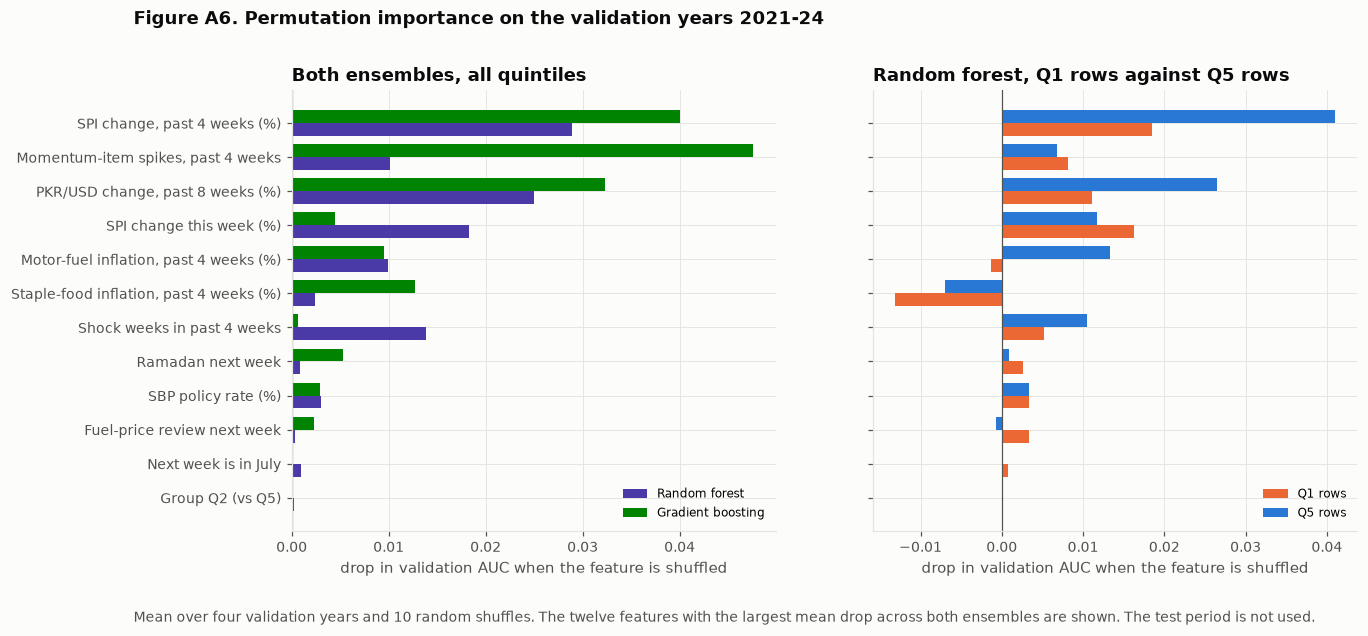

In [22]:
# Figure A6: what drives the forecasts, overall and for the poorest and richest quintiles
top = imp_tab.index[:12][::-1]
yy = np.arange(len(top))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharey=True)
ax = axes[0]
for k, n in enumerate(A.ENSEMBLES):
    ax.barh(yy + (k - 0.5) * 0.38, imp_tab.loc[top, f"{n} AUC drop"], height=0.38, color=COLORS[n], label=n)
ax.set_yticks(yy, [A.LABELS[f] for f in top])
ax.axvline(0, color=INK_SECONDARY, lw=0.8)
ax.set(xlabel="drop in validation AUC when the feature is shuffled", title="Both ensembles, all quintiles")
ax.legend(loc="lower right", fontsize=8)
ax = axes[1]
for k, g in enumerate(["Q1", "Q5"]):
    ax.barh(yy + (k - 0.5) * 0.38, imp_g.loc[top, g], height=0.38, color=GROUP_COLORS[g], label=f"{g} rows")
ax.axvline(0, color=INK_SECONDARY, lw=0.8)
ax.set(xlabel="drop in validation AUC when the feature is shuffled", title=f"{FINAL}, Q1 rows against Q5 rows")
ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Figure A6. Permutation importance on the validation years 2021-24", x=0.01, ha="left",
             fontweight="bold", color=INK, y=1.02)
caption(fig, "Mean over four validation years and 10 random shuffles. The twelve features with the largest mean drop "
             "across both ensembles are shown. The test period is not used.", y=-0.03)
fig.savefig(FIG_DIR / "figA6_feature_importance.png")
plt.show()

**Reading the drivers**
* **The forest relies on recent price momentum and the rupee.** Its leading features are the 4-week SPI change, the
  8-week rupee change, this week's SPI change, the shocks of the past four weeks and the momentum-item spikes. Gradient
  boosting leans most on the momentum spikes. These are the Milestone 3 drivers again.
* **Two features have negative importance.** Shuffling utility-tariff inflation or the 26-week shock rate slightly
  raises the forest's validation AUC, so in these years they added noise rather than signal (the ablation agrees).
* **Every leading signal matters more for Q5 than for Q1.** For the forest the 4-week SPI change is worth 0.041 of AUC on
  Q5 rows against 0.018 on Q1 rows, the rupee 0.027 against 0.011, motor-fuel inflation 0.013 against nothing, and
  perishables inflation 0.019 against 0.004. Only this week's SPI change and the fuel-review flag matter a little more
  for Q1. The signals in our data describe the shocks of the richest quintile better than those of the poorest, which
  is why the forest ranks Q1's weeks worse (§10).

## 12. Saved models and predictions

The five fitted pipelines are saved with `joblib` together with a model card (features, selected settings, thresholds,
cross-validated scores, final model) and the out-of-fold and test-period predictions that notebook 06 audits.

In [23]:
# Saving the five fitted pipelines, the out-of-fold and test predictions (to be used by notebook 06) and a model card
for n in MODELS:
    joblib.dump(fitted[n], MODEL_DIR / (n.lower().replace(" ", "_") + ".joblib"))
pred_oof = train[["week_end", "group", A.TARGET]].copy()
pred_test = test[["week_end", "group", A.TARGET]].copy()
for n in MODELS:
    pred_oof[n], pred_test[n] = oof[n], p_test[n]
pred_oof.to_csv(MODEL_DIR / "oof_predictions.csv", index=False)
pred_test.to_csv(MODEL_DIR / "test_predictions.csv", index=False)
card = {"features": A.FEATURES, "train_end": str(B.TRAIN_END.date()), "validation_years": B.VAL_YEARS,
        "selection": "within-year AUC (mean of the four per-fold ROC-AUCs)", "final_model": FINAL,
        "cost_fp": B.COST_FP, "cost_fn": B.COST_FN, "sklearn_version": sklearn.__version__,
        "models": {n: {"params": B._short(grid_res[n].iloc[0]["_params"]), "threshold": thr[n],
                       **{k: float(v) for k, v in A.cv_scores(y, oof[n], folds).items()}} for n in MODELS}}
(MODEL_DIR / "model_card.json").write_text(json.dumps(card, indent=2, default=str), encoding="utf-8")
print("Saved to", MODEL_DIR.relative_to(ROOT), sorted(p.name for p in MODEL_DIR.iterdir()))

Saved to models\m4_advanced ['decision_tree.joblib', 'gradient_boosting.joblib', 'knn.joblib', 'logistic_regression.joblib', 'model_card.json', 'oof_predictions.csv', 'random_forest.joblib', 'test_predictions.csv']


## 13. Summary of Milestone 4 modelling

**Findings**
1. **Two ensembles were built and tuned without leakage.** A random forest (128 settings) and gradient boosting
   (144 settings) were tuned by grid search on the same expanding-window folds as Milestone 3, together with the three
   re-tuned baselines. Selection used the within-year AUC.
2. **The learners are statistically tied.** Within-year AUCs run from 0.635 (gradient boosting) to 0.683 (KNN). The
   **random forest** (0.678) is the final model, because it is the best learner that can be retrained with the row
   weights the bias mitigations need.
3. **Ensembling did not beat the best baseline.** On the test period the forest's AUC (0.674) equals the Milestone 3
   KNN's (0.679) within noise. The limit is the weak signal, not the model's flexibility.
4. **Shuffled stratified K-fold would have reported an AUC of 0.83** for the forest, 0.15 more than the time-ordered design.
5. **The threshold problem remains.** In the calm test period no threshold beats never alerting, because the forest's
   alarms are right less than one time in six, and the probabilities over-predict by about half.
6. **The new features did not improve the ranking** in cross-validation.
7. **H4 is not supported** (p = 0.067). Only fuel reviews matter more for Q5. A pooled model beats quintile-own models.
8. **The pooled forest ranks Q5's weeks better than Q1's** (AUC 0.714 against 0.656), and its leading signals carry more
   information about Q5's shocks. This is the starting point of the fairness audit in notebook 06.

**What this means for the early-warning system.** A more flexible model does not find signal that is not in the data.
The useful gains are elsewhere: lead information on administered prices and perishable supplies, a threshold that
follows the regime (Milestone 5), and quintile-specific decisions (notebook 06).